<a href="https://colab.research.google.com/github/Nosimon-Nahar/LabReport-3_CSE-418/blob/main/Arithmetic_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

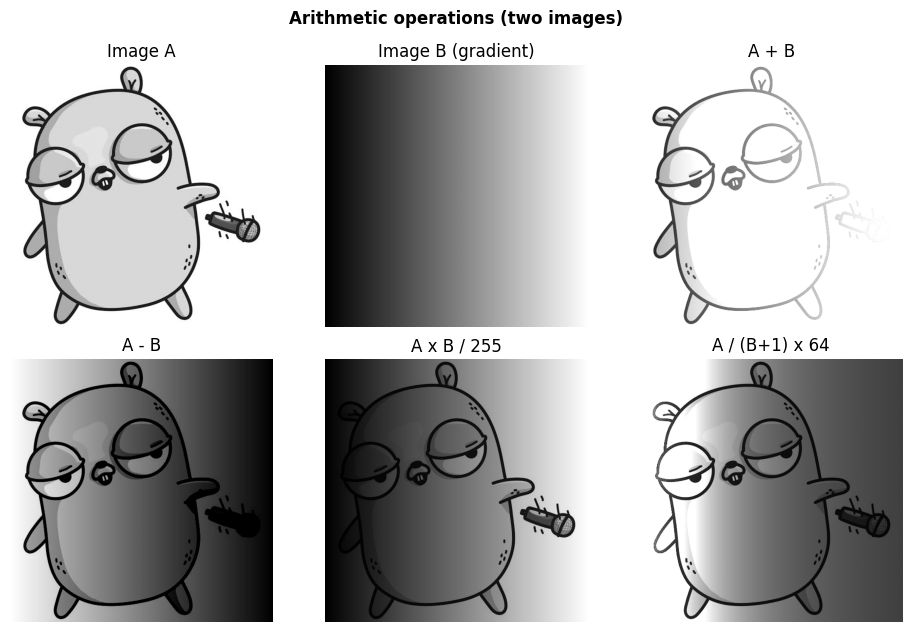

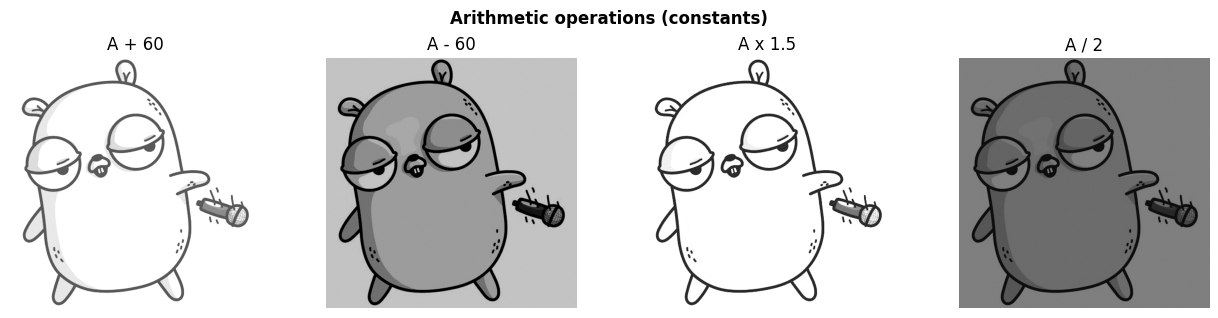

In [1]:
# The four arithmetic operations on an image
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_gray(path=None):
  # Load grayscale image; fall back to a synthetic test image.
    if path:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        return img
    x, y = np.meshgrid(np.linspace(0, 1, 512), np.linspace(0, 1, 512))
    img = 80 + 120 * x * y + 30 * np.sin(12 * y) * np.cos(8 * x)
    return np.clip(img, 0, 255).astype(np.uint8)

def clip_u8(a):
  # Clip to [0, 255] and convert back to uint8 (saturation).
    return np.clip(a, 0, 255).astype(np.uint8)

def show(images, titles, cols, title, fname):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows))
    for ax, im, t in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    fig.savefig(fname, dpi=120)

def main():
    img = load_gray("/content/images (3).jpg")
    h, w = img.shape

  # Second operand: horizontal gradient so every result is visible
    img2 = np.tile(np.linspace(0, 255, w).astype(np.uint8), (h, 1))

  # Use float to avoid uint8 wrap-around
    a = img.astype(np.float32)
    b = img2.astype(np.float32)

    add = clip_u8(a + b)                # addition (saturated)
    sub = clip_u8(a - b)                # subtraction (saturated)
    mul = clip_u8(a * b / 255.0)        # multiplication (rescaled)
    div = clip_u8(a / (b + 1.0) * 64.0) # division (+1 avoids /0, x64 for visibility)

    show([img, img2, add, sub, mul, div],
         ["Image A", "Image B (gradient)", "A + B", "A - B",
          "A x B / 255", "A / (B+1) x 64"],
         3, "Arithmetic operations (two images)", "arithmetic_two_images.png")

  # Operations with a constant (brightness / contrast)
    show([clip_u8(a + 60), clip_u8(a - 60), clip_u8(a * 1.5), clip_u8(a / 2.0)],
         ["A + 60", "A - 60", "A x 1.5", "A / 2"],
         4, "Arithmetic operations (constants)", "Arithmetic_constants.png")
    plt.show()

if __name__ == "__main__":
    main()